**Игровая модель**

Загрузка библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog, minimize

**Этап 1. Ввод данных**

Определим матрицу выигрышей

In [2]:
# Матрица выигрышей A(t), элементы — полиномы от t

def payoff_matrix(t):
    """
    Параметрическая матрица выигрышей A(t).
    Элементы — полиномы от t (степень не выше заданной).
    
    Пример: игра 3x3, где элементы линейно зависят от t.
    """
    A = np.array([
        [2 + 0.1*t,    1 - 0.05*t,   3 + 0.2*t],
        [1 + 0.15*t,   4 - 0.1*t,    2 + 0.05*t],
        [3 - 0.05*t,   2 + 0.1*t,    1 + 0.15*t]
    ])
    return A

# Проверка при t=0
A0 = payoff_matrix(0)
print(f"Матрица выигрышей A(0):\n{A0}")

Матрица выигрышей A(0):
[[2. 1. 3.]
 [1. 4. 2.]
 [3. 2. 1.]]


2. Решение матричной игры через ЛП

Проверим нижнюю цену игры

In [3]:
def positive_A(A):
  min_a = np.min(A)
  if min_a < 0:
    h = 2 * abs(min_a)
  else:
    h = 0
  return h

Решим двойственную задачу ЛП

In [4]:
def solve_dual_lp(A):
    n, m = A.shape

    # Вычисляем h и строим матрицу вспомогательную B
    h = positive_A(A)
    B = A + h

    # ----- Задача для игрока 1 (строки) -----
    # Минимизируем сумму p при B^T p >= 1, p >= 0
    c_p = np.ones(n)
    A_ub_p = -B.T      # -B^T p <= -1
    b_ub_p = -np.ones(m)
    bounds_p = [(0, None)] * n

    res_p = linprog(c_p, A_ub=A_ub_p, b_ub=b_ub_p,
                    bounds=bounds_p, method='highs')

    if not res_p.success:
        raise ValueError(f"ЛП для игрока 1 не сошлась: {res_p.message}")

    p_opt = res_p.x
    f_min = res_p.fun
    x_opt = p_opt / f_min

    # ----- Задача для игрока 2 (столбцы) -----
    # Максимизируем сумму q при B q <= 1, q >= 0
    c_q = -np.ones(m)   # минимизируем -sum(q) -> максимизируем sum(q)
    A_ub_q = B
    b_ub_q = np.ones(n)
    bounds_q = [(0, None)] * m

    res_q = linprog(c_q, A_ub=A_ub_q, b_ub=b_ub_q,
                    bounds=bounds_q, method='highs')

    if not res_q.success:
        raise ValueError(f"ЛП для игрока 2 не сошлась: {res_q.message}")

    q_opt = res_q.x
    g_max = -res_q.fun   # сумма q_j
    y_opt = q_opt / g_max

    # Цена игры
    v = 1 / f_min - h

    return x_opt, y_opt, v, h

3. Расчёт для дискретных t

In [5]:
t_values = range(20, 41)
results = []

for t in t_values:
    A_t = payoff_matrix(t)
    x, y, v, h = solve_dual_lp(A_t)

    results.append({
        't': t, 'h': h, 'v': v, 
        'x1': x[0], 'x2': x[1], 'x3': x[2],
        'y1': y[0], 'y2': y[1], 'y3': y[2]
    })

pd.DataFrame(results).T

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
t,20.0,21.000000,22.000000,23.000000,24.000000,25.000000,26.000000,27.000000,28.000000,29.000000,...,31.000000,32.000000,33.000000,34.000000,35.000,36.000000,37.000000,38.000000,39.000000,40.000000
h,0.0,0.100000,0.200000,0.300000,0.400000,0.500000,0.600000,0.700000,0.800000,0.900000,...,1.100000,1.200000,1.300000,1.400000,1.500,1.600000,1.700000,1.800000,1.900000,2.000000
v,3.0,3.025000,3.050000,3.075000,3.100000,3.125000,3.150000,3.175000,3.200000,3.225000,...,3.275000,3.300000,3.325000,3.350000,3.375,3.400000,3.425000,3.450000,3.475000,3.500000
x1,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000
x2,0.5,0.488636,0.479167,0.471154,0.464286,0.458333,0.453125,0.448529,0.444444,0.440789,...,0.434524,0.431818,0.429348,0.427083,0.425,0.423077,0.421296,0.419643,0.418103,0.416667
x3,0.5,0.511364,0.520833,0.528846,0.535714,0.541667,0.546875,0.551471,0.555556,0.559211,...,0.565476,0.568182,0.570652,0.572917,0.575,0.576923,0.578704,0.580357,0.581897,0.583333
y1,0.5,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,...,0.500000,0.500000,0.500000,0.500000,0.500,0.500000,0.500000,0.500000,0.500000,0.500000
y2,0.5,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,...,0.500000,0.500000,0.500000,0.500000,0.500,0.500000,0.500000,0.500000,0.500000,0.500000
y3,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000


4. Дробно-рациональная аппроксимация

In [8]:
from scipy.optimize import least_squares

class RationalModel:
    def __init__(self, u, weight=1.0):
        self.u = u
        self.weight = weight

    def fit(self, t, y):
        t, y = np.array(t), np.array(y)
        
        # начальное приближение
        p0_num = np.polyfit(t, y, min(1, self.u))[::-1] 
        p0_num = np.pad(p0_num, (0, self.u + 1 - len(p0_num)), 'constant')
        p0_den = np.zeros(self.u)
        p0 = np.concatenate([p0_num, p0_den])
        
        # Чтобы не было деления на ноль, добавим крошечный шум
        p0 += np.random.randn(len(p0)) * 1e-4

        def obj(params):
            a = params[:self.u + 1]
            b = np.concatenate(([1.0], params[self.u + 1:]))
            P = np.polyval(a[::-1], t)
            Q = np.polyval(b[::-1], t)
            
            # Защита от полюсов (где знаменатель близок к 0)
            Q_safe = np.where(np.abs(Q) < 1e-5, 1e-5, Q)
            
            # Считаем ошибку
            residuals = y - P / Q_safe
            
            # регуляризация
            reg = 1e-5 * np.sum(a**2) + 1e-5 * np.sum(b**2)
            
            return np.concatenate([residuals, [np.sqrt(reg)]]) * np.sqrt(self.weight)

        res = least_squares(obj, p0, method='trf', max_nfev=5000)
        
        self.num = res.x[:self.u + 1]
        self.den = np.concatenate(([1.0], res.x[self.u + 1:]))
        return self

    def predict(self, t):
        t = np.array(t).reshape(-1)
        P = np.polyval(self.num[::-1], t)
        Q = np.polyval(self.den[::-1], t)
        Q = np.where(np.abs(Q) < 1e-8, 1e-8, Q)
        return P / Q

def _format_rational(num, den):
    def poly_str(coeffs):
        terms = []
        # Идем от старшей степени к младшей для красоты
        for k in range(len(coeffs)-1, -1, -1):
            c = coeffs[k]
            if abs(c) < 1e-6: continue # Отсекаем нулевые (почти) коэффициенты
            
            if k == 0:
                terms.append(f"{c:.3f}")
            elif k == 1:
                terms.append(f"{c:+.3f}·t")
            else:
                terms.append(f"{c:+.3f}·t^{k}")
        return " ".join(terms) if terms else "0"
    
    # Убираем ведущий плюс
    num_str = poly_str(num).lstrip('+')
    den_str = poly_str(den).lstrip('+')
    return f"({num_str}) / ({den_str})"

def approximate(results, u, weights=(1/3, 1/3, 1/3)):
    t = np.array([r['t'] for r in results])
    x_true = np.array([[r['x1'], r['x2'], r['x3']] for r in results])
    y_true = np.array([[r['y1'], r['y2'], r['y3']] for r in results])
    v_true = np.array([r['v'] for r in results])

    x_models = [RationalModel(u, weight=weights[0]).fit(t, x_true[:, i]) for i in range(3)]
    y_models = [RationalModel(u, weight=weights[1]).fit(t, y_true[:, i]) for i in range(3)]
    v_model  = RationalModel(u, weight=weights[2]).fit(t, v_true)

    def predict(models, t):
        pred = np.column_stack([m.predict(t) for m in models])
        return pred / np.sum(pred, axis=1, keepdims=True)

    x_pred = predict(x_models, t)
    y_pred = predict(y_models, t)
    v_pred = v_model.predict(t)

    print("\n" + "=" * 60)
    print(f"АНАЛИТИЧЕСКИЕ ФОРМУЛЫ (u={u})")
    print("=" * 60)
    for i in range(3):
        print(f"x̃_{i+1}(t) = {_format_rational(x_models[i].num, x_models[i].den)}")
    for i in range(3):
        print(f"ỹ_{i+1}(t) = {_format_rational(y_models[i].num, y_models[i].den)}")
    print(f"ṽ(t)   = {_format_rational(v_model.num, v_model.den)}")

    Rx = np.sum((x_true - x_pred) ** 2)
    Ry = np.sum((y_true - y_pred) ** 2)
    Rv = np.sum((v_true - v_pred) ** 2)
    
    print(f"\nСкалярные невязки:")
    print(f"Rx = {Rx:.6f}, Ry = {Ry:.6f}, Rv = {Rv:.6f}")
    
    return x_models, y_models, v_model, v_pred

5. Графики

Введите максимальную степень полиномов в матрице (w):  2


Теоретическая степень аппроксимации: u_max = 2 * (max(3, 3) - 1) = 4

АНАЛИТИЧЕСКИЕ ФОРМУЛЫ (u=4)
x̃_1(t) = (0) / (0.000·t^4 -0.000·t^3 -0.000·t^2 +0.000·t 1.000)
x̃_2(t) = (-0.000·t^4 +0.000·t^3 -0.002·t^2 +0.000·t 0.000) / (-0.000·t^4 +0.001·t^3 +0.001·t^2 +0.000·t 1.000)
x̃_3(t) = (0.000·t^4 -0.005·t^3 +0.000·t^2 +0.001·t 0.000) / (0.001·t^4 -0.006·t^3 -0.001·t^2 -0.001·t 1.000)
ỹ_1(t) = (-0.003·t^4 -0.000·t^3 +0.003·t^2 +0.001·t 0.000) / (-0.006·t^4 -0.000·t^3 -0.002·t^2 -0.000·t 1.000)
ỹ_2(t) = (-0.003·t^4 -0.000·t^3 +0.003·t^2 +0.001·t 0.000) / (-0.006·t^4 -0.000·t^3 -0.002·t^2 -0.000·t 1.000)
ỹ_3(t) = (0.000·t -0.000) / (-0.000·t^4 +0.000·t^3 -0.000·t^2 1.000)
ṽ(t)   = (0.001·t^4 +0.046·t^3 +0.005·t^2 +0.006·t 0.001) / (0.000·t^4 +0.020·t^3 -0.010·t^2 -0.016·t 1.000)

Скалярные невязки:
Rx = 0.000000, Ry = 0.000000, Rv = 0.000000


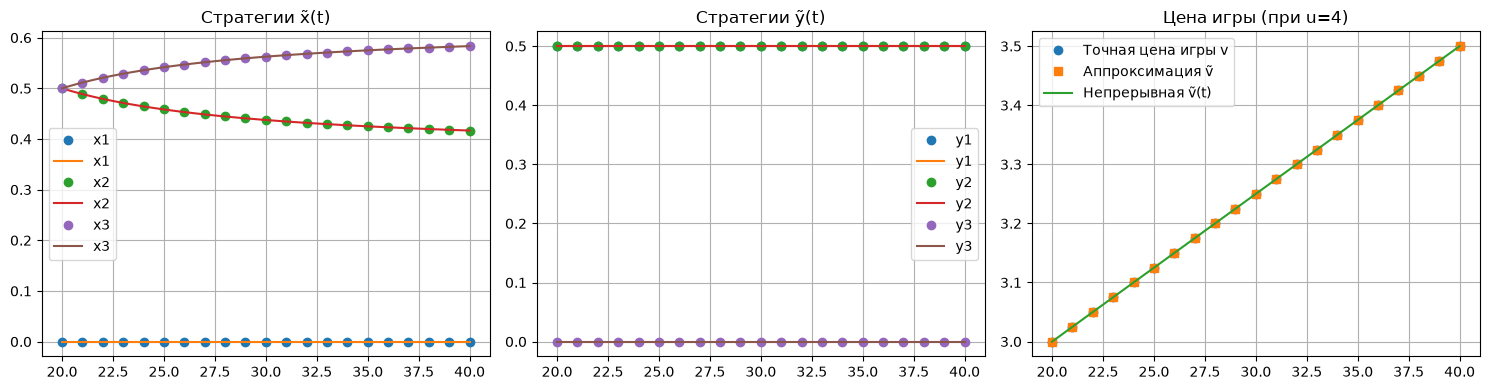

In [9]:
def plot_results(results, x_models, y_models, v_model, v_pred, u):
    t = np.array([r['t'] for r in results])
    t_cont = np.linspace(t.min(), t.max(), 100)

    def predict(models, t):
        pred = np.column_stack([m.predict(t) for m in models])
        return pred / np.sum(pred, axis=1, keepdims=True)

    x_true = np.array([[r['x1'], r['x2'], r['x3']] for r in results])
    y_true = np.array([[r['y1'], r['y2'], r['y3']] for r in results])
    v_true = np.array([r['v'] for r in results])

    x_cont = predict(x_models, t_cont)
    y_cont = predict(y_models, t_cont)
    v_cont = v_model.predict(t_cont)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))

    for i in range(3):
        ax[0].plot(t, x_true[:,i], 'o', t_cont, x_cont[:,i], '-', label=f'x{i+1}')
    ax[0].set_title('Стратегии x̃(t)'); ax[0].grid(True); ax[0].legend()

    for i in range(3):
        ax[1].plot(t, y_true[:,i], 'o', t_cont, y_cont[:,i], '-', label=f'y{i+1}')
    ax[1].set_title('Стратегии ỹ(t)'); ax[1].grid(True); ax[1].legend()

    ax[2].plot(t, v_true, 'o', label='Точная цена игры v')
    ax[2].plot(t, v_pred, 's', label='Аппроксимация ṽ')
    ax[2].plot(t_cont, v_cont, '-', label='Непрерывная ṽ(t)')
    ax[2].set_title(f'Цена игры (при u={u})'); ax[2].legend(); ax[2].grid(True)

    plt.tight_layout()
    plt.show()

# ===== ЗАПУСК =====
# Спрашиваем w (введи 1, если матрица линейна, 2 - если квадратична)
w = int(input("Введите максимальную степень полиномов в матрице (w): "))
n, m = 3, 3 
u_max = w * (max(n, m) - 1)
print(f"Теоретическая степень аппроксимации: u_max = {w} * (max({n}, {m}) - 1) = {u_max}")

weights = (1/3, 1/3, 1/3)

x_models, y_models, v_model, v_pred = approximate(results, u_max, weights=weights)
plot_results(results, x_models, y_models, v_model, v_pred, u_max)